<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20Regresi%20PBL/Praktikum%202%20(JS6R).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Mengimpor Library

In [1]:
# Mengimpor library yang diperlukan
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Langkah 2: Mengimpor dan Menggabungkan Dataset (cafes.csv & reviews.csv)

In [2]:
# Membaca data dari file CSV
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi data reviews per kafe
cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

# Gabungkan dataset cafes dan hasil agregasi reviews
dataset = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')

# Memilih fitur (X) dan target (y)
X = dataset[['review_count']].values
y = dataset['rating'].values

print("Ukuran data X:", X.shape)
print("Ukuran data y:", y.shape)

Ukuran data X: (94, 1)
Ukuran data y: (94,)


#Langkah 3: Feature Scaling

In [3]:
# Feature Scaling untuk X dan y
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).ravel() # .ravel() agar bentuknya 1D array

#Langkah 4: Fitting SVR ke Dataset

In [4]:
# Fitting SVR ke dataset (menggunakan kernel RBF)
regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled)

print("Model SVR berhasil dilatih!")

Model SVR berhasil dilatih!


#Langkah 5: Visualisasi Hasil SVR

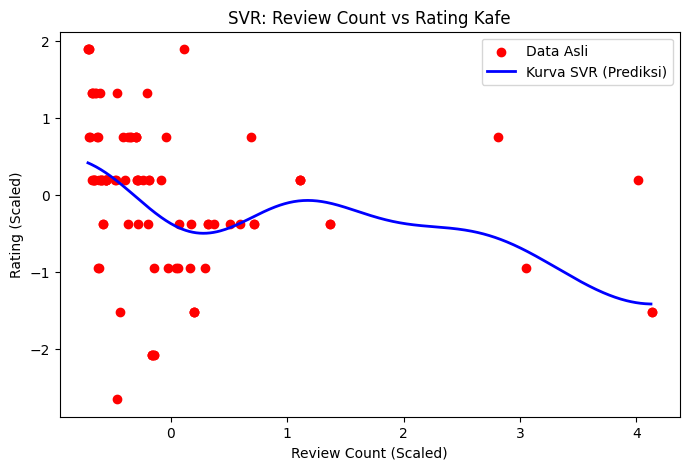

In [7]:
# Visualisasi hasil SVR (kurva yang lebih halus)
X_grid = np.arange(X_scaled.min(), X_scaled.max(), 0.01).reshape(-1, 1)

plt.figure(figsize=(8, 5))
plt.scatter(X_scaled, y_scaled, color='red', label='Data Asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', linewidth=2, label='Kurva SVR (Prediksi)')
plt.title('SVR: Review Count vs Rating Kafe')
plt.xlabel('Review Count (Scaled)')
plt.ylabel('Rating (Scaled)')
plt.legend()
plt.show()

#Langkah 6: Prediksi Hasil

In [8]:
# Prediksi hasil untuk jumlah ulasan tertentu (contoh: 500 review)
nilai_prediksi_input = np.array([[500.0]])

# Penskalaan fitur input
nilai_prediksi_scaled = sc_X.transform(nilai_prediksi_input)

# Melakukan prediksi menggunakan model SVR
prediksi_scaled = regressor.predict(nilai_prediksi_scaled)

# Mengembalikan hasil prediksi ke skala aslinya
prediksi_original = sc_y.inverse_transform(prediksi_scaled.reshape(-1, 1))

print(f"Prediksi Rating untuk Kafe dengan 500 Review: {prediksi_original[0][0]:.4f}")

Prediksi Rating untuk Kafe dengan 500 Review: 4.6649


#Langkah 7: Menampilkan Hasil

In [9]:
# Menampilkan hasil prediksi akhir
print("Hasil Prediksi Rating:", prediksi_original[0])

Hasil Prediksi Rating: [4.6648856]


#Langkah 8: Evaluasi Model SVR

In [10]:
# Evaluasi model SVR
y_pred_scaled = regressor.predict(X_scaled)

# Menghitung MAE, MSE, RMSE, dan R-squared
mae = mean_absolute_error(y_scaled, y_pred_scaled)
mse = mean_squared_error(y_scaled, y_pred_scaled)
rmse = np.sqrt(mse)
r2 = r2_score(y_scaled, y_pred_scaled)

print("--- Hasil Evaluasi Model SVR ---")
print(f"MAE     : {mae}")
print(f"MSE     : {mse}")
print(f"RMSE    : {rmse}")
print(f"R-squared: {r2}")

--- Hasil Evaluasi Model SVR ---
MAE     : 0.6457601260572781
MSE     : 0.7855750803438551
RMSE    : 0.8863267345307007
R-squared: 0.21442491965614474
